Langkah 1 — Pemahaman dan Pengambilan Dataset
Memuat dataset kolkata_weather_jan_june_2026.csv, menampilkan struktur data, mengekstrak fitur kategorikal, serta menentukan fitur (X) dan target (y).

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report, 
                             roc_curve, roc_auc_score)
import pickle
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
%matplotlib inline

In [31]:
# 1. Impor dataset ke Python menggunakan pandas
df = pd.read_csv('kolkata_weather_jan_june_2026.csv')
print('Shape data (Baris, Kolom):', df.shape)
display(df.head())

Shape data (Baris, Kolom): (1827, 17)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [32]:
print('\n--- Informasi Tipe Data ---')
df.info()


--- Informasi Tipe Data ---
<class 'pandas.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   str    
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   str    
 12  sunset                       1827 non-null   str    
 13  

In [33]:
print('\n--- Ringkasan Statistik ---')
display(df.describe(include='all'))


--- Ringkasan Statistik ---


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
count,1827,1827.000000,1827.00000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827,1827,1827.000000,1827,1.827000e+03,1.827000e+03
unique,1827,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1827,1827,NaN,1,NaN,NaN
top,2021-06-30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-06-30T04:55,2021-06-30T18:25,NaN,Kolkata,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,NaN,1827,NaN,NaN
mean,NaN,34.143952,26.26486,31.099234,22.477066,5.429119,5.429119,4.952928,13.782157,30.756596,192.212917,NaN,NaN,33185.460542,NaN,2.257260e+01,8.836390e+01
std,NaN,28.997216,4.05022,3.924558,4.847343,9.550693,9.550693,6.275264,5.106847,9.081119,100.165783,NaN,NaN,9824.134424,NaN,3.553686e-15,2.842949e-14
min,NaN,0.000000,15.00000,19.600000,10.200000,0.000000,0.000000,0.000000,4.500000,11.500000,0.000000,NaN,NaN,0.000000,NaN,2.257260e+01,8.836390e+01
25%,NaN,3.000000,23.40000,28.700000,18.600000,0.000000,0.000000,0.000000,10.000000,24.100000,135.000000,NaN,NaN,30684.495000,NaN,2.257260e+01,8.836390e+01
50%,NaN,51.000000,27.40000,31.300000,24.600000,0.400000,0.400000,2.000000,12.600000,29.500000,188.000000,NaN,NaN,36088.150000,NaN,2.257260e+01,8.836390e+01
75%,NaN,63.000000,29.10000,33.300000,26.200000,7.350000,7.350000,9.000000,16.600000,36.000000,258.000000,NaN,NaN,39550.540000,NaN,2.257260e+01,8.836390e+01


In [34]:
# 3. Feature Engineering & Penentuan Target Klasifikasi Biner (is_rainy)
data = df.copy()
data['time'] = pd.to_datetime(data['time'])
data['month'] = data['time'].dt.month

# Membentuk variabel kategorikal Musim (Season) dari bulan untuk di-encode pada Langkah 3
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    else:
        return 'Post-Monsoon'

data['season'] = data['month'].apply(get_season)

In [35]:
# Membentuk variabel kategorikal Arah Mata Angin (wind_compass) dari derajat angin
def get_wind_compass(deg):
    if deg >= 315 or deg < 45:
        return 'North'
    elif deg >= 45 and deg < 135:
        return 'East'
    elif deg >= 135 and deg < 225:
        return 'South'
    else:
        return 'West'

data['wind_compass'] = data['wind_direction_10m_dominant'].apply(get_wind_compass)

# Menentukan Target (y): is_rainy (1 = Hujan [weather_code >= 51], 0 = Tidak Hujan [weather_code < 51])
data['is_rainy'] = (data['weather_code'] >= 51).astype(int)

# Menentukan Fitur (X): 9 fitur atmosfer & kategorikal (menghapus kolom identitas/konstan & kolom curah hujan agar tidak bocor)
feature_cols = [
    'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min',
    'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant',
    'sunshine_duration', 'season', 'wind_compass'
]

X = data[feature_cols].copy()
y = data['is_rainy'].copy()

print('\nKolom Fitur (X):', list(X.columns))
print('Distribusi Target (y - is_rainy):\n', y.value_counts())


Kolom Fitur (X): ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration', 'season', 'wind_compass']
Distribusi Target (y - is_rainy):
 is_rainy
1    1021
0     806
Name: count, dtype: int64


Langkah 2 — Eksplorasi Data (EDA)
Memeriksa missing values, memvisualisasikan distribusi fitur dengan countplot dan histogram, serta menampilkan korelasi antar fitur menggunakan heatmap.

In [36]:
# 1. Periksa nilai kosong (missing values)
missing = data[feature_cols + ['is_rainy']].isnull().sum()
missing_pct = (missing / len(data)) * 100
missing_df = pd.DataFrame({'Jumlah Missing': missing, 'Persentase (%)': missing_pct.round(2)})
print("--- Pemeriksaan Missing Values ---")
display(missing_df)



--- Pemeriksaan Missing Values ---


,Jumlah Missing,Persentase (%)
temperature_2m_mean,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
wind_speed_10m_max,0,0.0
wind_gusts_10m_max,0,0.0
wind_direction_10m_dominant,0,0.0
sunshine_duration,0,0.0
season,0,0.0
wind_compass,0,0.0
is_rainy,0,0.0


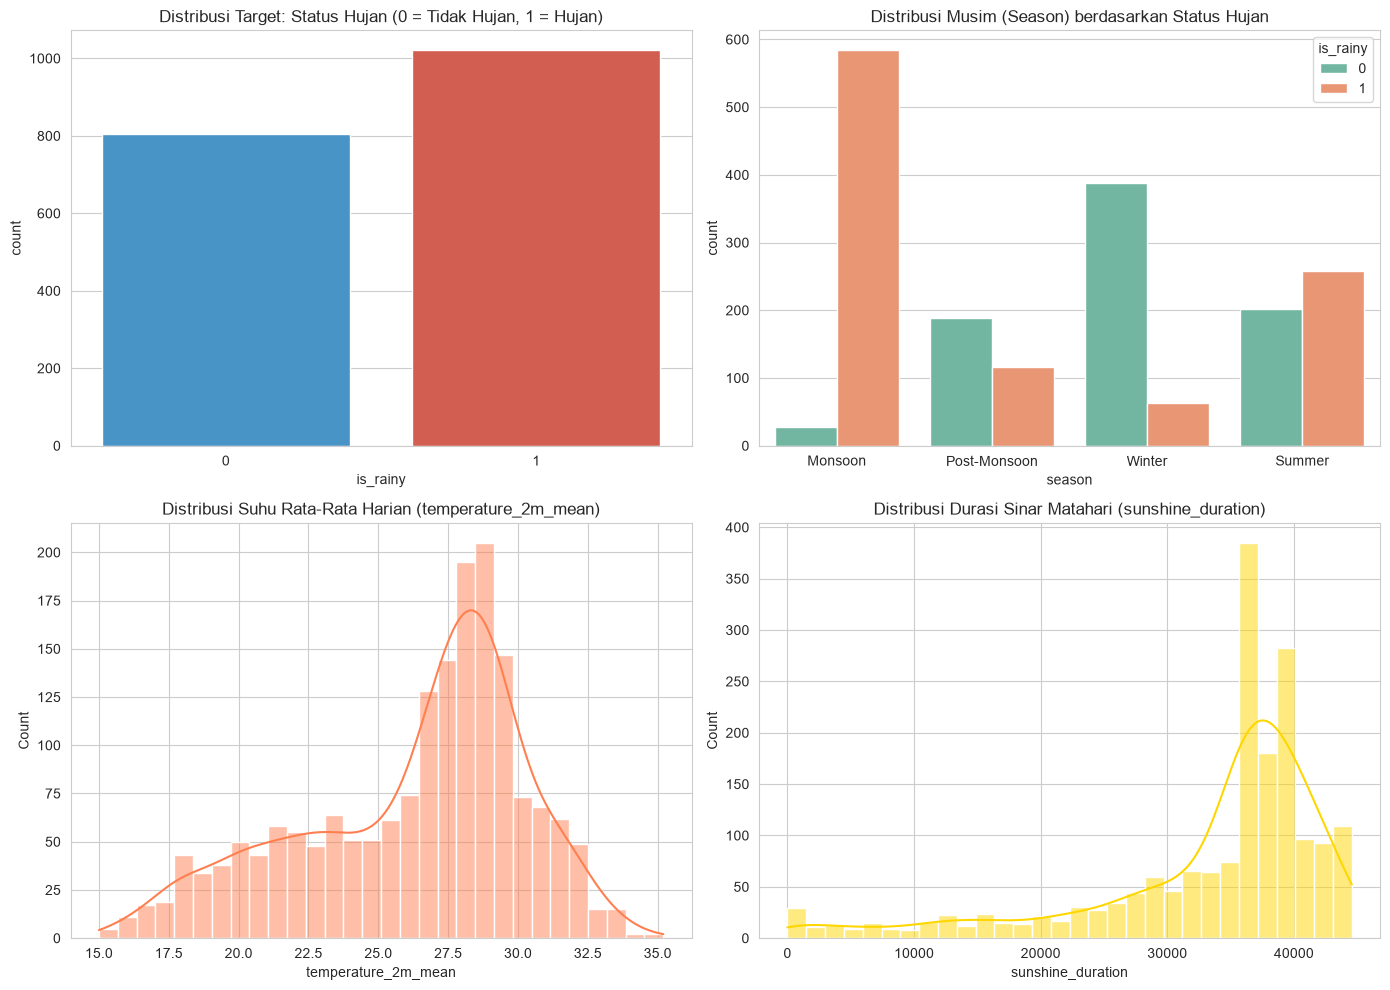

In [37]:
# 2. Tampilkan distribusi data tiap fitur menggunakan countplot dan histogram
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Countplot Target is_rainy
sns.countplot(data=data, x='is_rainy', palette=['#3498db', '#e74c3c'], ax=axes[0, 0])
axes[0, 0].set_title('Distribusi Target: Status Hujan (0 = Tidak Hujan, 1 = Hujan)')

# Countplot Musim (season)
sns.countplot(data=data, x='season', hue='is_rainy', palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('Distribusi Musim (Season) berdasarkan Status Hujan')

# Histogram Suhu Rata-rata
sns.histplot(data['temperature_2m_mean'], bins=30, kde=True, color='coral', ax=axes[1, 0])
axes[1, 0].set_title('Distribusi Suhu Rata-Rata Harian (temperature_2m_mean)')

# Histogram Durasi Sinar Matahari
sns.histplot(data['sunshine_duration'], bins=30, kde=True, color='gold', ax=axes[1, 1])
axes[1, 1].set_title('Distribusi Durasi Sinar Matahari (sunshine_duration)')

plt.tight_layout()
plt.show()



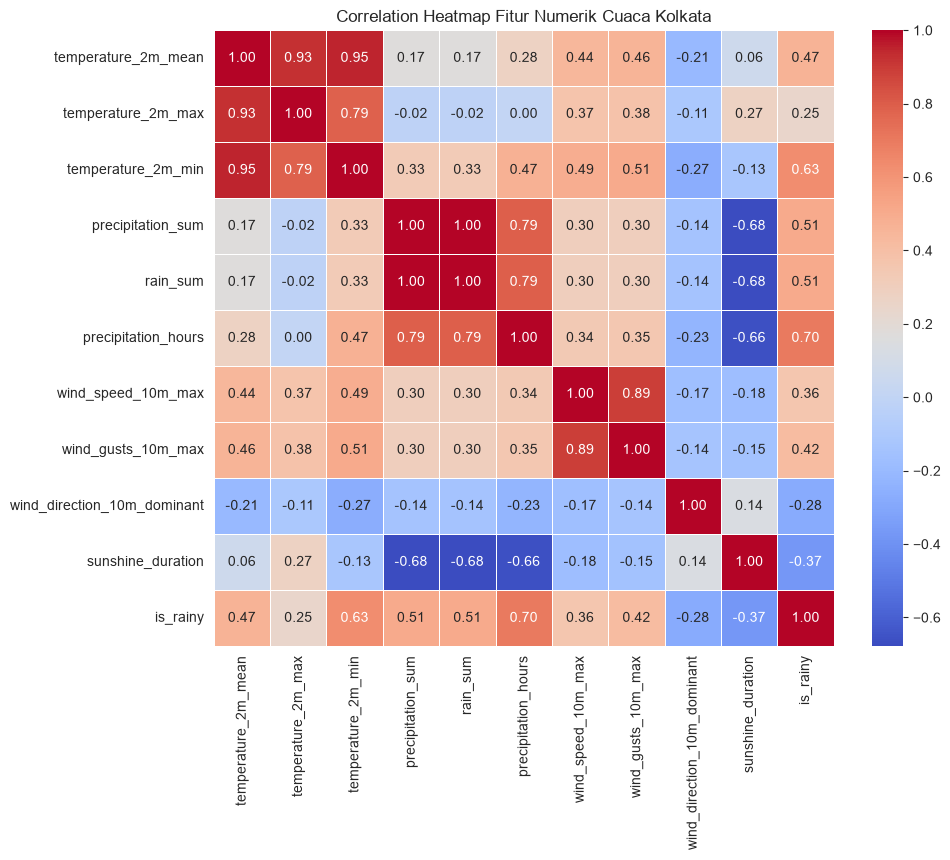

In [38]:
# 3. Visualisasikan korelasi antar fitur numerik dengan heatmap
num_cols = ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 
            'precipitation_sum', 'rain_sum', 'precipitation_hours', 
            'wind_speed_10m_max', 'wind_gusts_10m_max', 
            'wind_direction_10m_dominant', 'sunshine_duration', 'is_rainy']

plt.figure(figsize=(10, 8))
sns.heatmap(data[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap Fitur Numerik Cuaca Kolkata')
plt.show()

Langkah 3 — Pra-Pemrosesan Data (Bebas Data Leakage)
Membagi dataset menjadi 80% data latih (1.461 baris) dan 20% data uji (366 baris) terlebih dahulu, lalu melakukan imputasi (jika ada data kosong pada data baru), Label Encoding, dan StandardScaler yang di-fit hanya pada data latih agar tidak terjadi kebocoran data (data leakage).

In [39]:
# 1. Bagi dataset menjadi Data Latih (80%) dan Data Uji (20%) terlebih dahulu (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Jumlah data latih (80%):', X_train.shape[0])
print('Jumlah data uji (20%)  :', X_test.shape[0])



Jumlah data latih (80%): 1461
Jumlah data uji (20%)  : 366


In [40]:
# 2. Penanganan Missing Values (Tetap disiapkan dengan parameter dari X_train agar bebas Data Leakage)
num_features = ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min',
                'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant',
                'sunshine_duration']

for col in num_features:
    median_val = X_train[col].median()
    X_train[col] = X_train[col].fillna(median_val)
    X_test[col] = X_test[col].fillna(median_val)

for col in ['season', 'wind_compass']:
    mode_val = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_val)
    X_test[col] = X_test[col].fillna(mode_val)

In [41]:
# 3. Encoding terhadap variabel kategorikal dengan LabelEncoder (Fit hanya di X_train)
le_season = LabelEncoder()
le_wind = LabelEncoder()

X_train['season'] = le_season.fit_transform(X_train['season'])
X_test['season'] = le_season.transform(X_test['season'])

X_train['wind_compass'] = le_wind.fit_transform(X_train['wind_compass'])
X_test['wind_compass'] = le_wind.transform(X_test['wind_compass'])


In [42]:
# 4. Standarisasi fitur menggunakan StandardScaler (Fit hanya di X_train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Pra-pemrosesan selesai tanpa data leakage!")

Pra-pemrosesan selesai tanpa data leakage!


Langkah 4 — Membangun Model XGBoost
Melatih model menggunakan XGBClassifier dengan parameter n_estimators = 100, learning_rate = 0.1, max_depth = 5, dan random_state = 42.

In [43]:
# 1. Inisialisasi model XGBoost Classifier sesuai parameter praktikum
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='logloss'
)



In [44]:
# 2. Latih model menggunakan data latih
xgb_model.fit(X_train_scaled, y_train)



,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [45]:
# 3. Lakukan prediksi kelas dan probabilitas terhadap data uji
y_pred = xgb_model.predict(X_test_scaled)
y_proba = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("Model XGBoost berhasil dilatih dan diuji!")

Model XGBoost berhasil dilatih dan diuji!


Langkah 5 — Evaluasi Model
Menghitung nilai Accuracy, Precision, Recall, F1-Score, dan ROC-AUC Score beserta interpretasinya.

In [25]:
# Menghitung metrik evaluasi klasifikasi
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_proba)

metrics_df = pd.DataFrame({
    'Metrik Evaluasi': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC Score'],
    'Nilai': [acc, prec, rec, f1, auc_score]
})
display(metrics_df.round(4))

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Tidak Hujan (0)', 'Hujan (1)']))

,Metrik Evaluasi,Nilai
0,Accuracy,0.8770
1,Precision,0.8883
2,Recall,0.8927
3,F1-Score,0.8905
4,ROC-AUC Score,0.9468



=== Classification Report ===
                 precision    recall  f1-score   support

Tidak Hujan (0)       0.86      0.86      0.86       161
      Hujan (1)       0.89      0.89      0.89       205

       accuracy                           0.88       366
      macro avg       0.88      0.87      0.88       366
   weighted avg       0.88      0.88      0.88       366



Langkah 6 — Visualisasi Hasil & Penyimpanan Artefak (.pkl)
Menampilkan Confusion Matrix, ROC Curve, dan Feature Importance dari model XGBoost, lalu menyimpan seluruh objek ke file .pkl untuk digunakan di dashboard Streamlit.

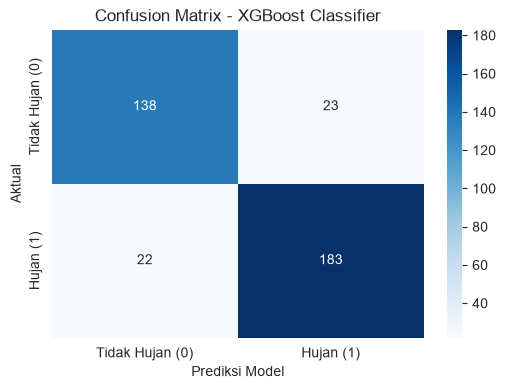

In [26]:
# 1. Tampilkan Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tidak Hujan (0)', 'Hujan (1)'],
            yticklabels=['Tidak Hujan (0)', 'Hujan (1)'])
plt.title('Confusion Matrix - XGBoost Classifier')
plt.xlabel('Prediksi Model')
plt.ylabel('Aktual')
plt.show()

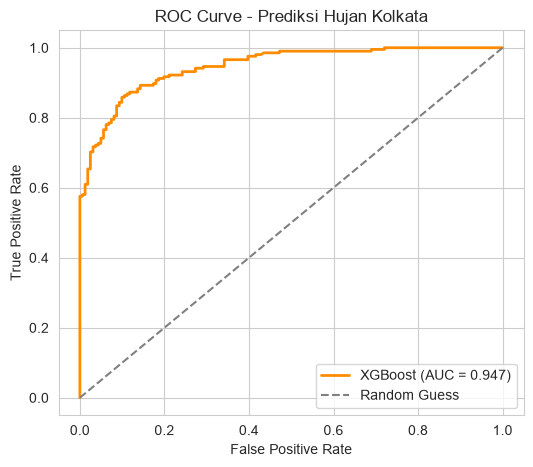

In [27]:

# 2. Buat grafik ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'XGBoost (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Prediksi Hujan Kolkata')
plt.legend(loc='lower right')
plt.show()

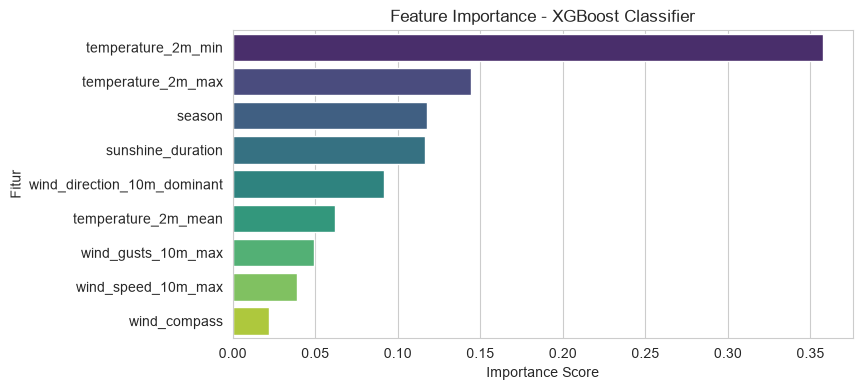

In [28]:
# 3. Visualisasikan Feature Importance dari model XGBoost
importances = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Feature Importance - XGBoost Classifier')
plt.xlabel('Importance Score')
plt.ylabel('Fitur')
plt.show()

In [29]:
# 4. Simpan Model, Scaler, Encoder, dan Data Evaluasi ke file .pkl untuk Streamlit
with open('model.pkl', 'wb') as f:
    pickle.dump(xgb_model, f)
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
with open('le_season.pkl', 'wb') as f:
    pickle.dump(le_season, f)
with open('le_wind.pkl', 'wb') as f:
    pickle.dump(le_wind, f)

eval_artifacts = {
    'metrics_df': metrics_df,
    'cm': cm,
    'fpr': fpr,
    'tpr': tpr,
    'auc': auc_score,
    'importances': importances,
    'data': data
}
with open('eval_data.pkl', 'wb') as f:
    pickle.dump(eval_artifacts, f)

print("Seluruh file (.pkl) berhasil disimpan! Siap dijalankan di Streamlit.")

Seluruh file (.pkl) berhasil disimpan! Siap dijalankan di Streamlit.
